<a href="https://colab.research.google.com/github/411221059/Analitik-dan-Visualisasi-data/blob/main/Analitik_Visualisasi_Data_P9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Membuat/menghubungkan ke file database
conn = sqlite3.connect('perpustakaan.db')
cursor = conn.cursor()

# Mengaktifkan dukungan foreign key (di SQLite default-nya nonaktif)
cursor.execute("PRAGMA foreign_keys = ON;")

# Hapus tabel lama agar notebook bisa dijalankan ulang tanpa error
cursor.execute("DROP TABLE IF EXISTS peminjaman;")
cursor.execute("DROP TABLE IF EXISTS buku;")
cursor.execute("DROP TABLE IF EXISTS anggota;")
conn.commit()
print("Koneksi ke database berhasil.")

Koneksi ke database berhasil.


In [2]:
cursor.execute("""
CREATE TABLE buku (
    id      INTEGER PRIMARY KEY,
    judul   TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun   INTEGER
);
""")

cursor.execute("""
CREATE TABLE anggota (
    id    INTEGER PRIMARY KEY,
    nama  TEXT NOT NULL,
    email TEXT UNIQUE
);
""")

cursor.execute("""
CREATE TABLE peminjaman (
    id          INTEGER PRIMARY KEY,
    id_anggota  INTEGER NOT NULL,
    id_buku     INTEGER NOT NULL,
    tgl_pinjam  DATE NOT NULL,
    tgl_kembali DATE,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku)    REFERENCES buku(id)
);
""")
conn.commit()
print("Tabel buku, anggota, dan peminjaman berhasil dibuat.")

Tabel buku, anggota, dan peminjaman berhasil dibuat.


In [3]:
data_buku = [
    (1, 'Laskar Pelangi',        'Andrea Hirata',          2005),
    (2, 'Bumi Manusia',          'Pramoedya Ananta Toer',  1980),
    (3, 'Negeri 5 Menara',       'Ahmad Fuadi',            2009),
    (4, 'Ronggeng Dukuh Paruk',  'Ahmad Tohari',           1982),
    (5, 'Cantik Itu Luka',       'Eka Kurniawan',          2002),
]

data_anggota = [
    (1, 'Andi Pratama',  'andi@email.com'),
    (2, 'Budi Santoso',  'budi@email.com'),
    (3, 'Citra Lestari', 'citra@email.com'),
]

cursor.executemany("INSERT INTO buku VALUES (?, ?, ?, ?);", data_buku)
cursor.executemany("INSERT INTO anggota VALUES (?, ?, ?);", data_anggota)
conn.commit()

print("Data buku:")
display(pd.read_sql_query("SELECT * FROM buku", conn))
print("Data anggota:")
display(pd.read_sql_query("SELECT * FROM anggota", conn))

Data buku:


,id,judul,penulis,tahun
0,1,Laskar Pelangi,Andrea Hirata,2005
1,2,Bumi Manusia,Pramoedya Ananta Toer,1980
2,3,Negeri 5 Menara,Ahmad Fuadi,2009
3,4,Ronggeng Dukuh Paruk,Ahmad Tohari,1982
4,5,Cantik Itu Luka,Eka Kurniawan,2002


Data anggota:


,id,nama,email
0,1,Andi Pratama,andi@email.com
1,2,Budi Santoso,budi@email.com
2,3,Citra Lestari,citra@email.com


In [4]:
data_peminjaman = [
    (1, 1, 1, '2026-11-01', '2026-11-08'),
    (2, 2, 3, '2026-11-03', '2026-11-13'),
    (3, 1, 2, '2026-11-10', '2026-11-15'),
    (4, 3, 5, '2026-11-18', None),   # belum dikembalikan -> NULL
]

cursor.executemany("INSERT INTO peminjaman VALUES (?, ?, ?, ?, ?);", data_peminjaman)
conn.commit()

display(pd.read_sql_query("SELECT * FROM peminjaman", conn))

,id,id_anggota,id_buku,tgl_pinjam,tgl_kembali
0,1,1,1,2026-11-01,2026-11-08
1,2,2,3,2026-11-03,2026-11-13
2,3,1,2,2026-11-10,2026-11-15
3,4,3,5,2026-11-18,None


In [5]:
query_join = """
SELECT p.id          AS id_pinjam,
       a.nama        AS nama_anggota,
       b.judul       AS judul_buku,
       p.tgl_pinjam,
       p.tgl_kembali
FROM peminjaman p
JOIN anggota a ON p.id_anggota = a.id
JOIN buku    b ON p.id_buku    = b.id
ORDER BY p.tgl_pinjam;
"""

cursor.execute(query_join)
print(f"{'ID':<4}{'Nama Anggota':<16}{'Judul Buku':<22}{'Tgl Pinjam':<13}{'Tgl Kembali'}")
print("-" * 68)
for row in cursor.fetchall():
    tgl_kembali = row[4] if row[4] else "Belum kembali"
    print(f"{row[0]:<4}{row[1]:<16}{row[2]:<22}{row[3]:<13}{tgl_kembali}")

ID  Nama Anggota    Judul Buku            Tgl Pinjam   Tgl Kembali
--------------------------------------------------------------------
1   Andi Pratama    Laskar Pelangi        2026-11-01   2026-11-08
2   Budi Santoso    Negeri 5 Menara       2026-11-03   2026-11-13
3   Andi Pratama    Bumi Manusia          2026-11-10   2026-11-15
4   Citra Lestari   Cantik Itu Luka       2026-11-18   Belum kembali


In [6]:
query_group = """
SELECT a.nama          AS nama_anggota,
       COUNT(p.id)     AS jumlah_buku_dipinjam
FROM anggota a
LEFT JOIN peminjaman p ON a.id = p.id_anggota
GROUP BY a.id, a.nama
ORDER BY jumlah_buku_dipinjam DESC;
"""

cursor.execute(query_group)
print(f"{'Nama Anggota':<16}{'Jumlah Buku'}")
print("-" * 28)
for nama, jumlah in cursor.fetchall():
    print(f"{nama:<16}{jumlah}")

Nama Anggota    Jumlah Buku
----------------------------
Andi Pratama    2
Budi Santoso    1
Citra Lestari   1


In [7]:
df_pinjam = pd.read_sql_query(query_join, conn)   # hasil 1c
df_jumlah = pd.read_sql_query(query_group, conn)  # hasil 1d

print("DataFrame peminjaman (dari 1c):")
display(df_pinjam)
print("DataFrame jumlah per anggota (dari 1d):")
display(df_jumlah)

DataFrame peminjaman (dari 1c):


,id_pinjam,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Andi Pratama,Laskar Pelangi,2026-11-01,2026-11-08
1,2,Budi Santoso,Negeri 5 Menara,2026-11-03,2026-11-13
2,3,Andi Pratama,Bumi Manusia,2026-11-10,2026-11-15
3,4,Citra Lestari,Cantik Itu Luka,2026-11-18,None


DataFrame jumlah per anggota (dari 1d):


,nama_anggota,jumlah_buku_dipinjam
0,Andi Pratama,2
1,Budi Santoso,1
2,Citra Lestari,1


In [8]:
# Ubah kolom tanggal menjadi tipe datetime
df_pinjam['tgl_pinjam']  = pd.to_datetime(df_pinjam['tgl_pinjam'])
df_pinjam['tgl_kembali'] = pd.to_datetime(df_pinjam['tgl_kembali'])

# Status pengembalian
df_pinjam['status'] = df_pinjam['tgl_kembali'].apply(
    lambda x: 'Belum kembali' if pd.isna(x) else 'Sudah kembali')

# Durasi peminjaman (hari). Untuk yang belum kembali, dihitung sampai hari ini.
hari_ini = pd.Timestamp.today().normalize()
df_pinjam['durasi_hari'] = (df_pinjam['tgl_kembali'].fillna(hari_ini)
                            - df_pinjam['tgl_pinjam']).dt.days

display(df_pinjam)

# Statistik durasi (hanya peminjaman yang sudah selesai)
selesai = df_pinjam[df_pinjam['status'] == 'Sudah kembali']
print("\nStatistik durasi peminjaman yang sudah selesai:")
print(selesai['durasi_hari'].describe())
print(f"\nRata-rata durasi : {selesai['durasi_hari'].mean():.1f} hari")
print(f"Durasi terlama   : {selesai['durasi_hari'].max()} hari")
print(f"Durasi tercepat  : {selesai['durasi_hari'].min()} hari")

# Pola peminjaman
print("\nJumlah peminjaman per status:")
print(df_pinjam['status'].value_counts())

print("\nAnggota paling aktif meminjam:")
print(df_pinjam['nama_anggota'].value_counts().head(1))

print("\nRata-rata durasi per anggota:")
print(df_pinjam.groupby('nama_anggota')['durasi_hari'].mean())

,id_pinjam,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali,status,durasi_hari
0,1,Andi Pratama,Laskar Pelangi,2026-11-01,2026-11-08,Sudah kembali,7
1,2,Budi Santoso,Negeri 5 Menara,2026-11-03,2026-11-13,Sudah kembali,10
2,3,Andi Pratama,Bumi Manusia,2026-11-10,2026-11-15,Sudah kembali,5
3,4,Citra Lestari,Cantik Itu Luka,2026-11-18,NaT,Belum kembali,6



Statistik durasi peminjaman yang sudah selesai:
count     3.000000
mean      7.333333
std       2.516611
min       5.000000
25%       6.000000
50%       7.000000
75%       8.500000
max      10.000000
Name: durasi_hari, dtype: float64

Rata-rata durasi : 7.3 hari
Durasi terlama   : 10 hari
Durasi tercepat  : 5 hari

Jumlah peminjaman per status:
status
Sudah kembali    3
Belum kembali    1
Name: count, dtype: int64

Anggota paling aktif meminjam:
nama_anggota
Andi Pratama    2
Name: count, dtype: int64

Rata-rata durasi per anggota:
nama_anggota
Andi Pratama      6.0
Budi Santoso     10.0
Citra Lestari     6.0
Name: durasi_hari, dtype: float64


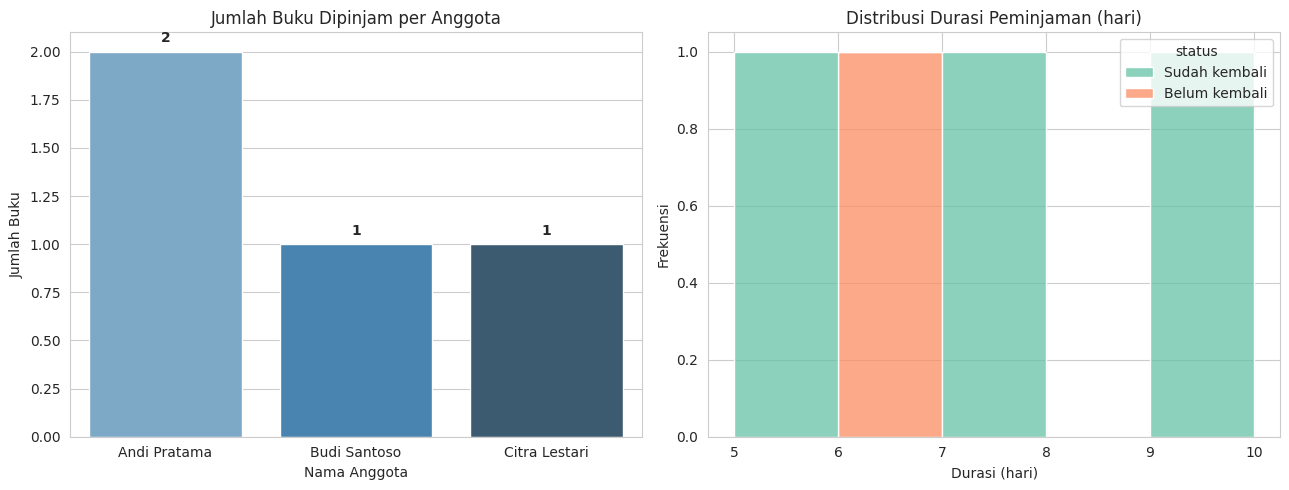

In [9]:
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grafik 1: Diagram batang jumlah buku dipinjam per anggota
sns.barplot(data=df_jumlah, x='nama_anggota', y='jumlah_buku_dipinjam',
            hue='nama_anggota', palette='Blues_d', legend=False, ax=axes[0])
axes[0].set_title('Jumlah Buku Dipinjam per Anggota')
axes[0].set_xlabel('Nama Anggota')
axes[0].set_ylabel('Jumlah Buku')
for i, v in enumerate(df_jumlah['jumlah_buku_dipinjam']):
    axes[0].text(i, v + 0.05, str(v), ha='center', fontweight='bold')

# Grafik 2: Histogram durasi peminjaman
sns.histplot(data=df_pinjam, x='durasi_hari', hue='status',
             bins=5, multiple='stack', palette='Set2', ax=axes[1])
axes[1].set_title('Distribusi Durasi Peminjaman (hari)')
axes[1].set_xlabel('Durasi (hari)')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

In [10]:
conn.close()
print("Koneksi database ditutup.")

Koneksi database ditutup.
